In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Study hours
X = np.array([1, 2, 3, 4, 5, 6, 7, 8], dtype=float)

# 0 = Fail, 1 = Pass
y = np.array([0, 0, 0, 0, 1, 1, 1, 1], dtype=float)

In [2]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def predict_probability(X, w, b):
    z = X @ w + b
    return sigmoid(z)

In [6]:
# binary cross-entropy loss
def compute_logistic_loss(y, p):
    eps = 1e-15
    p = np.clip(p, eps, 1 - eps)

    return -np.mean(
        y * np.log(p) + (1 - y) * np.log(1 - p)
    )


In [7]:
def train_logistic_regression(
    X, y, learning_rate=0.1, epochs=2000
):
    # Convert X to a 2D matrix: samples x features
    X = np.asarray(X, dtype=float).reshape(-1, 1)
    y = np.asarray(y, dtype=float)

    n, n_features = X.shape
    w = np.zeros(n_features)
    b = 0.0
    losses = []

    for epoch in range(epochs):
        # 1. Forward pass
        p = sigmoid(X @ w + b)

        # 2. Calculate gradients
        error = p - y
        dw = (X.T @ error) / n
        db = np.mean(error)

        # 3. Update parameters
        w -= learning_rate * dw
        b -= learning_rate * db

        # 4. Calculate updated loss
        p_updated = sigmoid(X @ w + b)
        losses.append(compute_logistic_loss(y, p_updated))

    return w, b, losses


w, b, losses = train_logistic_regression(X, y)

print("Weight:", w)
print("Bias:", b)
print("Final loss:", losses[-1])

Weight: [1.74427359]
Bias: -7.632308076009153
Final loss: 0.11036356715339814


In [8]:
X_2d = X.reshape(-1, 1)

probabilities = sigmoid(X_2d @ w + b)
predictions = (probabilities >= 0.5).astype(int)

print("Probabilities:", probabilities.ravel())
print("Predictions:", predictions)
print("Actual:", y.astype(int))

Probabilities: [0.00276476 0.01561537 0.0832118  0.3418156  0.74820465 0.94445075
 0.98982513 0.99820666]
Predictions: [0 0 0 0 1 1 1 1]
Actual: [0 0 0 0 1 1 1 1]


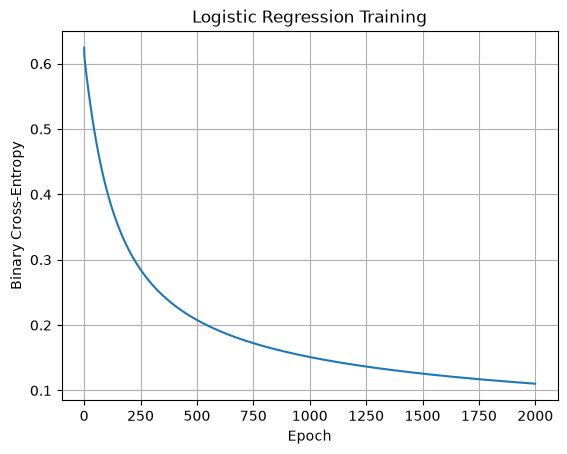

In [ ]:
# Plot the loss and decision boundary

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy")
plt.title("Logistic Regression Training")
plt.grid(True)
plt.show()

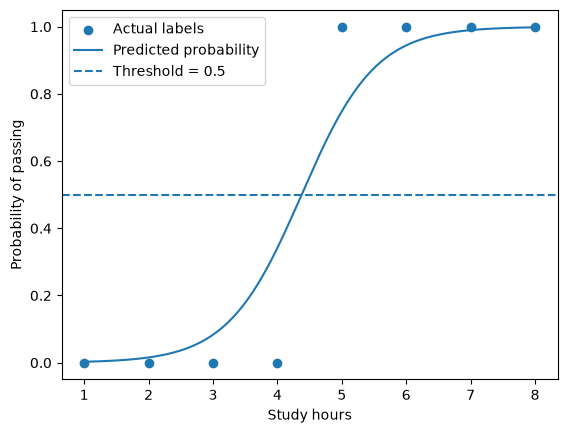

In [ ]:
# To visualize the classification boundary:

x_grid = np.linspace(X.min(), X.max(), 200).reshape(-1, 1) # linspace generates a 1-D array of numbers that are evenly spaced over a specified interval
p_grid = sigmoid(x_grid @ w + b)

plt.scatter(X, y, label="Actual labels")
plt.plot(x_grid, p_grid, label="Predicted probability")
plt.axhline(0.5, linestyle="--", label="Threshold = 0.5") # adds a horizontal line across the plot axes
plt.xlabel("Study hours")
plt.ylabel("Probability of passing")
plt.legend()
plt.show()